# Preprocessing dan EDA — dataset penelitian

**Tujuan:** melihat apa yang terjadi dari lima sumber Pyrfume sampai dataset siap dipakai model, memakai artefak eksperimen yang sudah selesai. **Notebook ini baca-saja**: tidak mengunduh, membersihkan ulang, melatih, atau mengganti hasil eksperimen.

Data akhir: **6.686 molekul unik, 109 label, 5.353 train, 1.333 test**. Lima sumber dipilih karena relevan dengan konteks parfum, tetapi **tidak berarti setiap molekul adalah bahan parfum yang terverifikasi**. Angka dan grafik di bawah dihitung dari file tersimpan, bukan diketik manual.

## Setup

Jalankan dari folder `KODE_ML` atau root repositori. Sumber asli dan aturan cleaning ada di `alignment/perfume_data.py`; fitur penelitian di `alignment/descriptors_v7.py`. Notebook ini menunjukkan jejak datanya tanpa membuat build baru.

In [1]:
from pathlib import Path
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo_env = os.environ.get("ML_REPO_ROOT")
candidates = [Path(repo_env)] if repo_env else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "alignment" / "protocol_v7.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Jalankan dari root repo/KODE_ML atau set ML_REPO_ROOT.")
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data/builds/perfume-five-grouped-v2"
FITUR = ROOT / "data/builds/perfume-m2048-d8-v7"
plt.rcParams.update({"figure.figsize": (9, 4.7), "font.size": 10, "axes.grid": True})
print("Dataset:", DATA)
print("Fitur eksperimen:", FITUR)

Dataset: C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\data\builds\perfume-five-grouped-v2
Fitur eksperimen: C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\data\builds\perfume-m2048-d8-v7


## Steps — 1. Load Data dan jejak seleksi

Kelima tabel sumber dibaca oleh fungsi `load_sources`, lalu identitas molekul dan label disatukan oleh `merge_sources`. Audit di bawah mencatat berapa baris awal, diterima, dan ditolak per sumber. Baris dari sumber berbeda yang menunjuk molekul sama digabung menjadi satu SMILES kanonik.

In [2]:
audit = json.loads((DATA / "audit.json").read_text(encoding="utf-8"))
source_audit = pd.DataFrame.from_dict(audit["sources"], orient="index")
source_audit.index.name = "Sumber"
source_audit["ditolak"] = source_audit["rows"] - source_audit["accepted"]
print(source_audit[["rows", "accepted", "ditolak", "missing_identity", "multifragment", "empty_labels", "unmapped_labels"]].to_string())
print("Total baris sumber:", int(source_audit["rows"].sum()))
print("Total baris diterima sebelum gabung duplikat molekul:", int(source_audit["accepted"].sum()))

             rows  accepted  ditolak  missing_identity  multifragment  empty_labels  unmapped_labels
Sumber                                                                                              
goodscents   4626      4104      522                 0            183             4              335
ifra         1146      1118       28                 0             28             0                0
leffingwell  3522      3408      114                 0              0             0              114
arctander    3102      2440      662               278            102           209               73
sigma         941       707      234               204              0             0               30
Total baris sumber: 13337
Total baris diterima sebelum gabung duplikat molekul: 11777


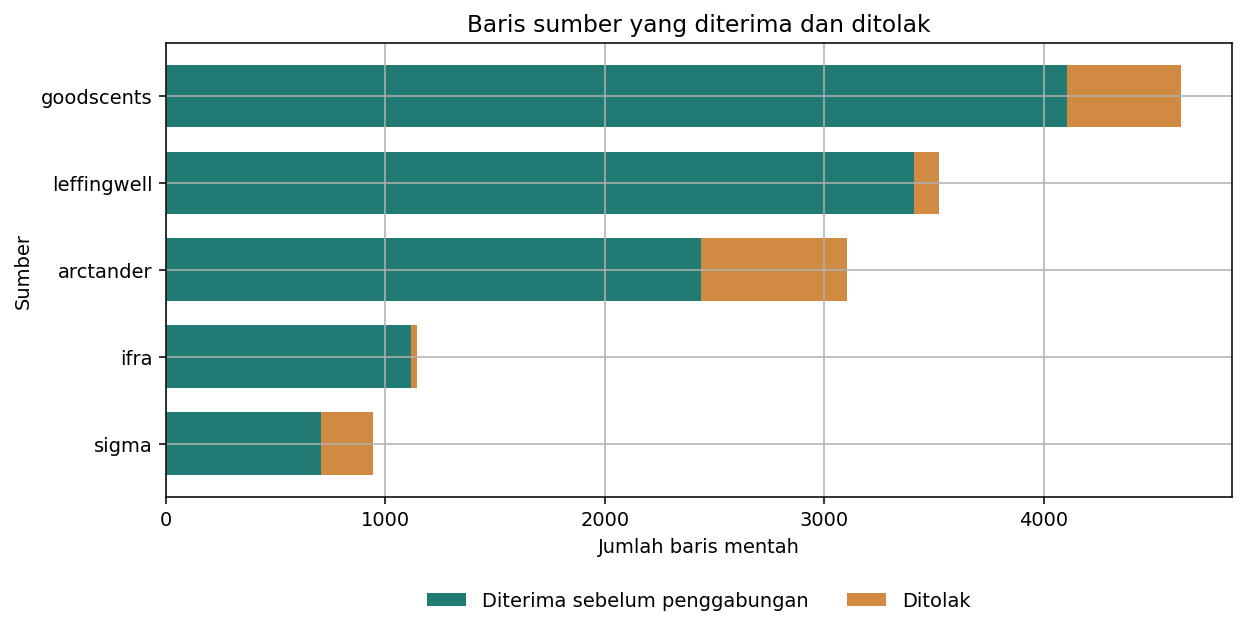

In [3]:
ax = source_audit.sort_values("rows")[["accepted", "ditolak"]].plot.barh(
    stacked=True, color=["#217a73", "#d08a41"], width=0.72)
ax.set(title="Baris sumber yang diterima dan ditolak", xlabel="Jumlah baris mentah", ylabel="Sumber")
ax.legend(["Diterima sebelum penggabungan", "Ditolak"],
          frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
plt.tight_layout()
plt.show()

Baris ditolak terutama karena struktur tidak cocok/terdiri dari beberapa komponen, label kosong, atau label tidak masuk kamus. Detail alasan berasal dari audit, bukan diputuskan ulang di notebook.

### 2. Cleaning, SMILES, dan duplikat

Alur asli menolak identitas kosong, SMILES gagal dibaca RDKit, atau lebih dari satu fragmen. Label disamakan dengan kamus IFRA dan alias eksplisit; molekul sama digabung memakai SMILES kanonik. Di sini kita cek hasil akhirnya.

In [4]:
records = pd.read_csv(DATA / "records.csv")
records["labels"] = records["labels"].map(json.loads)
records["sources"] = records["sources"].map(json.loads)
print("Molekul unik:", len(records))
print("SMILES kosong:", int(records["smiles"].isna().sum()))
print("Duplikat SMILES akhir:", int(records["smiles"].duplicated().sum()))
print("Baris tanpa label tercatat:", int(records["labels"].map(len).eq(0).sum()))
print("Molekul muncul di >1 sumber:", int(records["sources"].map(len).gt(1).sum()))
print(records[["smiles", "labels", "sources"]].head(3).to_string(index=False))

Molekul unik: 6686
SMILES kosong: 0
Duplikat SMILES akhir: 0
Baris tanpa label tercatat: 0
Molekul muncul di >1 sumber: 2808
             smiles                               labels                 sources
      BrC=Cc1ccccc1     [floral, green, hyacinth, leafy] [arctander, goodscents]
C#CC(C)(O)CCC=C(C)C [dry, musk like, sweet, waxy, woody]            [goodscents]
          C#CC(C)CO                    [ethereal, green]             [arctander]


In [5]:
reasons = source_audit[["missing_identity", "invalid_smiles", "multifragment", "empty_labels", "unmapped_labels", "invalid_behavior"]].sum().sort_values(ascending=False)
print("Alasan baris tidak dipakai (jumlah baris):")
print(reasons.to_string())
print("Baris diterima yang kemudian tergabung karena identitas molekul sama:",
      int(source_audit["accepted"].sum() - len(records)))

Alasan baris tidak dipakai (jumlah baris):
unmapped_labels     552
missing_identity    482
multifragment       313
empty_labels        213
invalid_smiles        0
invalid_behavior      0
Baris diterima yang kemudian tergabung karena identitas molekul sama: 5091


### 3. Label encoding dan distribusi

Setiap kolom target bernilai 1 jika label tercatat untuk molekul, 0 jika tidak tercatat. **Nol bukan bukti laboratorium bahwa molekul itu pasti tidak punya aroma tersebut.** Hanya label yang memenuhi dukungan minimal pada train yang dipakai; pemilihan tidak melihat test.

In [6]:
manifest = json.loads((DATA / "dataset_manifest.json").read_text(encoding="utf-8"))
labels = manifest["labels"]
selection = pd.read_csv(DATA / "label_selection.csv")
with np.load(DATA / "train.npz", allow_pickle=False) as saved:
    y_train = saved["truth"].copy()
    train_rows = saved["row_index"].copy()
with np.load(DATA / "test.npz", allow_pickle=False) as saved:
    y_test = saved["truth"].copy()
    test_rows = saved["row_index"].copy()
print(f"Target train: {y_train.shape}, target test: {y_test.shape}; tipe: {y_train.dtype}")
print("Label dalam kamus IFRA:", len(manifest["taxonomy"]))
print("Label terpilih:", int(selection["selected"].sum()))
print("Positif per label di train, min/median/max:",
      int(y_train.sum(0).min()), float(np.median(y_train.sum(0))), int(y_train.sum(0).max()))

Target train: (5353, 109), target test: (1333, 109); tipe: uint8
Label dalam kamus IFRA: 184
Label terpilih: 109
Positif per label di train, min/median/max: 32 100.0 1987


Lima label paling jarang pada train:
rooty        32
popcorn      34
narcissus    34
celery       34
raspberry    35


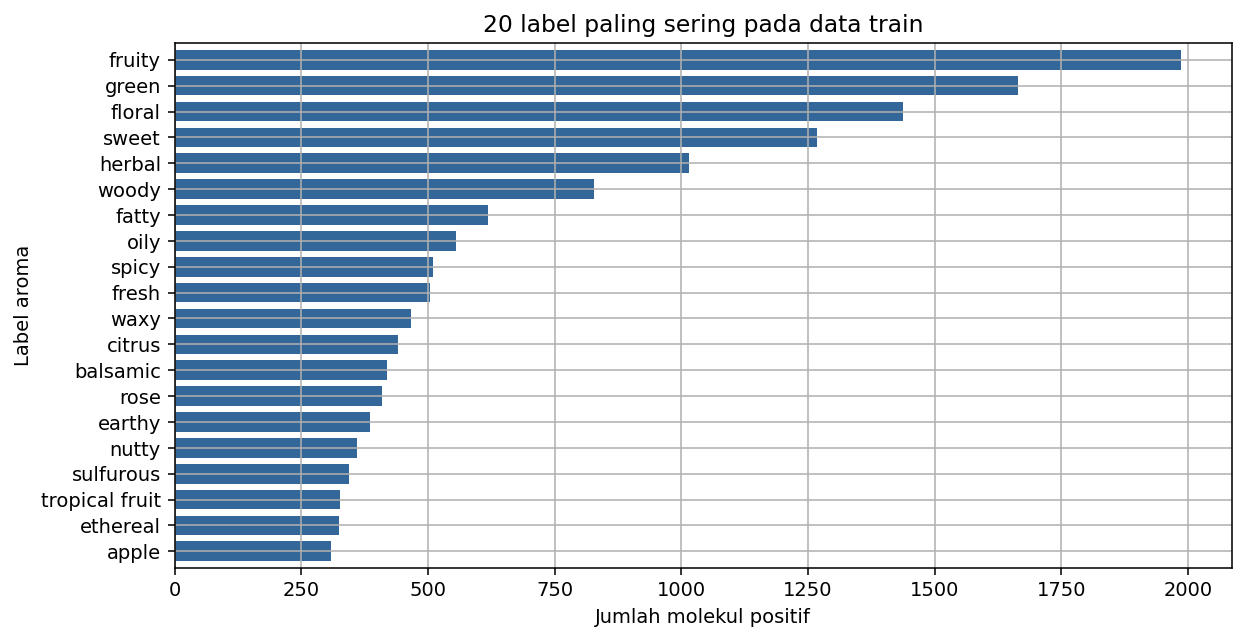

In [7]:
positive = pd.Series(y_train.sum(axis=0), index=labels, name="train positif").sort_values()
top = positive.tail(20)
ax = top.plot.barh(color="#336699", width=0.76)
ax.set(title="20 label paling sering pada data train", xlabel="Jumlah molekul positif", ylabel="Label aroma")
plt.tight_layout()
plt.show()
print("Lima label paling jarang pada train:")
print(positive.head(5).to_string())

Label sangat tidak seimbang. Karena itu AP, precision, recall, dan F1 perlu dibaca bersama; accuracy saja bisa menyesatkan.

### 4. Fitur RDKit yang dipakai

SMILES diubah menjadi **2048 angka biner** Morgan (radius 2) dan **8 angka deskriptor RDKit**. A/C memakai Morgan saja (2048 fitur), B/D menggabungkan keduanya (2056 fitur). Build awal `train.npz` memang menyimpan 1024+5 sebagai artefak lama; eksperimen utama membaca `FITUR/features.npz` di bawah.

In [8]:
from alignment.descriptors_v7 import DESCRIPTORS8, calculate, calculate_morgan

with np.load(FITUR / "features.npz", allow_pickle=False) as saved:
    morgan = saved["morgan"].copy()
    descriptors = saved["descriptors"].copy()
    feature_rows = saved["row_index"].copy()
    descriptor_names = saved["names"].tolist()
assert descriptor_names == list(DESCRIPTORS8)
assert np.array_equal(feature_rows, np.arange(len(records)))
print("Morgan:", morgan.shape, morgan.dtype, "nilai unik:", np.unique(morgan))
print("Deskriptor:", descriptors.shape, descriptors.dtype)
print("Urutan deskriptor:", descriptor_names)
print("Jumlah fitur A/C:", morgan.shape[1], "| B/D:", morgan.shape[1] + descriptors.shape[1])

Morgan: (6686, 2048) uint8 nilai unik: [0 1]
Deskriptor: (6686, 8) float32
Urutan deskriptor: ['MolWt', 'MolLogP', 'NumHDonors', 'NumHAcceptors', 'TPSA', 'NumRotatableBonds', 'HeavyAtomCount', 'RingCount']
Jumlah fitur A/C: 2048 | B/D: 2056


In [9]:
sample_smiles = records.loc[0, "smiles"]
assert np.array_equal(calculate_morgan([sample_smiles])[0], morgan[0])
assert np.array_equal(calculate([sample_smiles])[0], descriptors[0])
print("Contoh SMILES:", sample_smiles)
print("Bit aktif:", int(morgan[0].sum()), "dari", morgan.shape[1])
print(pd.Series(descriptors[0], index=descriptor_names, name="Nilai").to_string())

Contoh SMILES: BrC=Cc1ccccc1
Bit aktif: 15 dari 2048
MolWt                183.048004
MolLogP                3.052200
NumHDonors             0.000000
NumHAcceptors          0.000000
TPSA                   0.000000
NumRotatableBonds      1.000000
HeavyAtomCount         9.000000
RingCount              1.000000


### 5. Split berkelompok

Molekul dengan struktur/fitur satu grup tidak boleh tersebar antara train dan test. Validasi memakai **5 seed × 5 fold**, tetapi bukan 25 set test independen. Hasil test tetap satu holdout terpisah.

In [10]:
groups = pd.read_csv(DATA / "groups.csv")
assert len(groups) == len(records)
assert np.array_equal(groups["source_row"].to_numpy(), records["source_row"].to_numpy())
train_groups = set(groups.loc[train_rows, "group_id"])
test_groups = set(groups.loc[test_rows, "group_id"])
overlap = train_groups & test_groups
print("Train/test:", len(train_rows), len(test_rows))
print("Jumlah grup:", groups["group_id"].nunique())
print("Grup yang menyeberang train-test:", len(overlap))
assert not overlap

Train/test: 5353 1333
Jumlah grup: 5363
Grup yang menyeberang train-test: 0


## Checks

Ukuran data, label, fitur, dan pembagian di bawah harus cocok dengan artefak eksperimen. Ini pemeriksaan identitas dasar, bukan klaim bahwa anotasi antar-dataset sudah sempurna.

In [11]:
assert len(records) == 6686
assert y_train.shape == (5353, 109) and y_test.shape == (1333, 109)
assert morgan.shape == (6686, 2048) and descriptors.shape == (6686, 8)
assert not records["smiles"].isna().any() and records["smiles"].is_unique
assert not overlap
print("OK: identitas baris, shape, duplikat, dan pemisahan grup sesuai artefak eksperimen.")

OK: identitas baris, shape, duplikat, dan pemisahan grup sesuai artefak eksperimen.


## Next Steps

Lanjut ke `01_fitur.py` → `02_split.py` → `03_optuna.py` → `04_training_evaluasi.py` → `05_prediksi.py`. Untuk detail implementasi pembersihan, buka `alignment/perfume_data.py`; notebook ini memeriksa keluaran yang sudah dibekukan. **Catatan sidang:** label yang tidak dicatat diperlakukan sebagai 0 saat evaluasi, sehingga noise anotasi antarsumber tetap menjadi batas penelitian.